# Final test: the TCN and the Compact pooled GRU on the test matches

This notebook shows how the two final models do on the test matches, side by side, as the web app shows them. It reads saved results only: it trains, tunes and runs nothing. The test matches were set aside when the data was split and appear nowhere in the [model comparison notebook](tactic-model-comparison.ipynb).

Each question explains what is shown and how to read it, then the evidence, then a line of key numbers and the checks behind every statement. Appendix A lists the files read and how they were made.

The TCN on shared clip features is the selected model, chosen by nested cross-validation (see the comparison notebook, 6.2). The final TCN and GRU are both shown on the test set side by side, as in the app; the test results do not change the choice.

In [1]:
# @title Load the saved results
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

%matplotlib inline

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "stratscout").is_dir() and (p / "AGENTS.md").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the CV-DL repository or its notebooks folder.")
sys.path.insert(0, str(ROOT))
from stratscout.config import TACTIC_CLASSES  # noqa: E402
from stratscout.tactic_tcn import classification_metrics  # noqa: E402  (the scoring behind the TCN's saved test report)

# Every folder this notebook reads, listed once (Appendix A says how each was made).
RUNS = {
    "tcn_final": "runs/tactic-tcn-clipdata-final",  # final TCN: models, saved test report and test predictions
    "gru_final": "runs/tactic-gru-clipdata-final-20261121",  # final Compact pooled GRU: models and training report
    "gru_test": "runs/tactic-gru-clipdata-test-20261121",  # the GRU's one test run, with the TCN check
    "tcn_nested": "runs/tactic-tcn-clipdata-nested-20261120",  # nested cross-validation, TCN (training matches only)
    "gru_nested": "runs/tactic-clipdata-nested-20261120",  # nested cross-validation, Compact pooled GRU (gru/)
}
run = {key: ROOT / path for key, path in RUNS.items()}
missing = [path for key, path in RUNS.items() if not run[key].is_dir()]
if missing:
    raise FileNotFoundError("Run folders not found: " + ", ".join(missing) + " (see Appendix A)")

CLASSES = list(TACTIC_CLASSES)
KINDS = ["tcn", "gru"]
MODEL = {"tcn": "TCN", "gru": "Compact pooled GRU"}
COLOURS = {"tcn": "#41ab5d", "gru": "#6a51a3"}
MATCH_NAMES = {
    "navi-falcons-mirage-cologne-major": "NaVi vs Falcons",
    "vitality-falcons-mirage-esl-pro-league-season-24": "Vitality vs Falcons",
    "spirit-falcons-mirage-cologne-major": "Spirit vs Falcons",
    "furia-falcons-mirage-cologne-major-2026": "Furia vs Falcons",
    "mouz-betboom-mirage-iem-bejing-2026": "MOUZ vs BetBoom",
    "aurora-vitality-mirage-esl-pro-league-season-24": "Aurora vs Vitality",
}
FONT = "font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px;"
TOLERANCE = 1e-9
ROUNDING = 1e-4 + 1e-9  # one step of the 4-decimal rounding in the prediction files


def show_table(name, df, decimals=3):
    """Text columns left, number columns right; scores to three decimals; no index. `name`
    is the table's fixed HTML id, so rerunning the notebook leaves the saved output unchanged."""
    numbers = [c for c in df.columns if len(df) and all(isinstance(v, (int, float, np.number)) and not isinstance(v, bool) for v in df[c])]
    fmt_ = {c: (lambda v, d=decimals: f"{v:d}" if isinstance(v, (int, np.integer)) else f"{v:.{d}f}") for c in numbers}
    styles = [
        {"selector": "th", "props": FONT + " font-weight: 600; padding: 4px 10px; border-bottom: 1px solid #999;"},
        {"selector": "td", "props": FONT + " padding: 4px 10px;"},
    ]
    for i, column in enumerate(df.columns):
        styles.append({"selector": f"th.col_heading.col{i}", "props": f"text-align: {'right' if column in numbers else 'left'};"})
    styler = df.style.set_uuid(name).hide(axis="index").format(fmt_).set_table_styles(styles)
    text = [c for c in df.columns if c not in numbers]
    if text:
        styler = styler.set_properties(subset=text, **{"text-align": "left"})
    if numbers:
        styler = styler.set_properties(subset=numbers, **{"text-align": "right"})
    display(HTML(styler.to_html()))  # HTML only: the Styler's text form holds a memory address


def say(text):
    display(Markdown(text))


def claims(checks):
    """Each check is (claim, test). A claim that fails stops the notebook."""
    for claim, holds in checks:
        if not holds():
            raise AssertionError(f"The answer above no longer holds: {claim}")
    say("**Checked:** " + "; ".join(claim for claim, _ in checks) + ".")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def read_csv(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def probs_of(row):
    return np.array([float(row[f"p_{c}"]) for c in CLASSES])


def match_of(clip_id):
    return clip_id.split(".")[0]


def short(clip_id):
    """The clip's number within its match (the full ID also names the labeller)."""
    return clip_id.split(".")[-1]


def macro(y, predicted):
    return classification_metrics(y, predicted)["macro_f1"]


def per_match(y, predicted, matches):
    y, predicted, matches = map(np.asarray, (y, predicted, matches))
    return {m: macro(y[matches == m], predicted[matches == m]) for m in sorted(set(matches))}


# --- The final models' test results ---------------------------------------------------
tcn_report = read_json(run["tcn_final"] / "report.json")
tcn_config = read_json(run["tcn_final"] / "config.json")
gru_train = read_json(run["gru_final"] / "report.json")
gru_test = read_json(run["gru_test"] / "report.json")
app = read_json(run["gru_test"] / "app-results.json")
tcn_rows = [r for r in read_csv(run["tcn_final"] / "predictions.csv") if r["model"] == "tcn"]
gru_rows = read_csv(run["gru_test"] / "predictions.csv")

clips = [r["clip_id"] for r in tcn_rows]
truth = {r["clip_id"]: CLASSES.index(r["true"]) for r in tcn_rows}
y = np.array([truth[c] for c in clips])
matches = np.array([match_of(c) for c in clips])
TEST_MATCHES = sorted(set(matches))
gru_by = {(r["seed"], r["clip_id"]): r for r in gru_rows}
GRU_SEEDS = sorted({r["seed"] for r in gru_rows} - {"ensemble"}, key=int)
gru_seed_probs = {s: np.array([probs_of(gru_by[(s, c)]) for c in clips]) for s in GRU_SEEDS}
ensemble = {
    "tcn": np.array([probs_of(r) for r in tcn_rows]),
    "gru": np.array([probs_of(gru_by[("ensemble", c)]) for c in clips]),
}
predicted = {k: p.argmax(1) for k, p in ensemble.items()}
by_app = {r["clip"]: r for r in app}

# Main test number for both: macro-F1 pooled over all test clips, per seed, then mean and SD
# over seeds (the TCN's saved method), with the seed ensemble next to it.
seed_f1 = {
    "tcn": list(tcn_report["models"]["tcn"]["test"]["seed_macro_f1"]),  # saved; per-seed predictions were not saved
    "gru": [macro(y, gru_seed_probs[s].argmax(1)) for s in GRU_SEEDS],  # recomputed from the saved per-seed predictions
}
test = {
    k: dict(
        seed_f1=seed_f1[k],
        mean=float(np.mean(seed_f1[k])),
        sd=float(np.std(seed_f1[k])),
        ensemble=classification_metrics(y, predicted[k]),
        per_match=per_match(y, predicted[k], matches),
    )
    for k in KINDS
}
for k in KINDS:
    test[k]["per_match_mean"] = float(np.mean(list(test[k]["per_match"].values())))
majority_class = tcn_report["majority"]["class"]
majority = dict(
    pooled=classification_metrics(y, [CLASSES.index(majority_class)] * len(y)),
    per_match=per_match(y, [CLASSES.index(majority_class)] * len(y), matches),
)
majority["per_match_mean"] = float(np.mean(list(majority["per_match"].values())))

# --- Nested cross-validation on the training matches (the comparison notebook's runs) -----
cv = {}
parts = [read_json(p) for p in sorted(run["tcn_nested"].glob("tcn-*.json"))]
seed_probs_cv = {p["outer_match"]: {s["seed"]: np.array(s["probs"]) for s in p["seeds"]} for p in parts}
y_cv = {p["outer_match"]: p["y"] for p in parts}
cv["tcn"] = dict(
    per_match={m: macro(y_cv[m], np.mean(list(s.values()), 0).argmax(1)) for m, s in seed_probs_cv.items()},
    per_seed={seed: float(np.mean([macro(y_cv[m], s[seed].argmax(1)) for m, s in seed_probs_cv.items()])) for seed in parts[0]["config"]["seeds"]},
)
nested_gru = read_csv(run["gru_nested"] / "gru" / "predictions.csv")
by_clip = {}
for r in nested_gru:
    by_clip.setdefault(r["clip_id"], (CLASSES.index(r["truth"]), {}))[1][int(r["seed"])] = probs_of(r)
cv_clips = sorted(by_clip)
cv_y = np.array([by_clip[c][0] for c in cv_clips])
cv_matches = np.array([match_of(c) for c in cv_clips])
cv_seeds = sorted(next(iter(by_clip.values()))[1])
cv["gru"] = dict(
    per_match=per_match(cv_y, np.array([np.mean(list(by_clip[c][1].values()), 0) for c in cv_clips]).argmax(1), cv_matches),
    per_seed={s: float(np.mean(list(per_match(cv_y, np.array([by_clip[c][1][s] for c in cv_clips]).argmax(1), cv_matches).values()))) for s in cv_seeds},
)
for k in KINDS:
    cv[k]["per_match_mean"] = float(np.mean(list(cv[k]["per_match"].values())))
    cv[k]["nested"] = float(np.mean(list(cv[k]["per_seed"].values())))
    cv[k]["nested_sd"] = float(np.std(list(cv[k]["per_seed"].values())))
TRAIN_MATCHES = sorted(cv["tcn"]["per_match"])

In [2]:
# @title Check the saved results
done = []
# 1. The TCN: the saved test predictions give the saved test report.
saved = tcn_report["models"]["tcn"]["test"]
ours = test["tcn"]["ensemble"]
assert abs(ours["macro_f1"] - saved["ensemble"]["macro_f1"]) < TOLERANCE and abs(ours["accuracy"] - saved["ensemble"]["accuracy"]) < TOLERANCE
assert ours["confusion"] == saved["ensemble"]["confusion"]
assert all(abs(ours["per_class"][c][m] - saved["ensemble"]["per_class"][c][m]) < TOLERANCE for c in CLASSES for m in ("precision", "recall", "f1"))
assert abs(test["tcn"]["mean"] - saved["seed_macro_f1_mean"]) < TOLERANCE and abs(test["tcn"]["sd"] - saved["seed_macro_f1_std"]) < TOLERANCE
done.append("the TCN's saved test predictions reproduce its saved test report (seed ensemble, per class, confusion)")
# 2. The TCN check in the GRU's test run: predict_clips reproduced those saved predictions.
check = gru_test["tcn_check"]
assert check["passed"] and check["clips"] == len(clips) == check["same_predicted_class"] and check["max_abs_probability_difference"] <= ROUNDING
assert all(by_app[c]["predictions"]["tcn"]["tactic"] == CLASSES[predicted["tcn"][i]] for i, c in enumerate(clips))
assert all(abs(by_app[c]["predictions"]["tcn"]["probabilities"][k] - ensemble["tcn"][i][j]) <= ROUNDING for i, c in enumerate(clips) for j, k in enumerate(CLASSES))
done.append(f"predict_clips reproduced the TCN's saved test predictions on all {len(clips)} clips (largest probability difference {check['max_abs_probability_difference']:.4f})")
# 3. The GRU: its ensemble is the mean of its seeds, the app's output matches, the report matches.
assert np.allclose(ensemble["gru"], np.mean(list(gru_seed_probs.values()), 0), atol=1e-12, rtol=0)
assert all(by_app[c]["predictions"]["gru"]["probabilities"][k] == round(float(ensemble["gru"][i][j]), 4) for i, c in enumerate(clips) for j, k in enumerate(CLASSES))
assert all(by_app[c]["predictions"]["gru"]["tactic"] == CLASSES[predicted["gru"][i]] for i, c in enumerate(clips))
g = gru_test["gru"]["test"]
assert np.allclose(g["seed_macro_f1"], test["gru"]["seed_f1"], atol=TOLERANCE, rtol=0) and g["ensemble"]["confusion"] == test["gru"]["ensemble"]["confusion"]
assert abs(g["ensemble"]["macro_f1"] - test["gru"]["ensemble"]["macro_f1"]) < TOLERANCE and abs(g["per_match_mean"]["ensemble"] - test["gru"]["per_match_mean"]) < TOLERANCE
done.append("the GRU's ensemble is the mean of its three seeds, and its saved report and the app's output match its predictions")
# 4. Both models scored the same clips with the same labels.
assert sorted(clips) == sorted(by_app) == sorted({r["clip_id"] for r in gru_rows}) and len(set(clips)) == len(clips)
assert all(CLASSES.index(r["true"]) == truth[r["clip_id"]] for r in gru_rows)
assert gru_test["clips"] == len(clips) and set(gru_test["matches"]) == set(TEST_MATCHES)
assert not set(TEST_MATCHES) & set(TRAIN_MATCHES)
done.append(f"both models scored the same {len(clips)} clips of {len(TEST_MATCHES)} test matches, none of them a training match")
# 5. The final models are the ones cross-validated, and both learnt from the same training clips.
assert tcn_config == parts[0]["config"] and all(p["config"] == tcn_config for p in parts)
gru_cv_settings = read_json(run["gru_nested"] / "gru" / "config.json")["temporal"]
assert {k: gru_cv_settings[k] for k in ("projection", "hidden", "dropout", "readout")} == gru_train["settings"]["gru"] == gru_test["gru"]["settings"]["gru"]
assert gru_test["gru"]["epochs"] == gru_train["chosen_epoch"]
assert sum(tcn_report["clips"]["train"].values()) == gru_train["clips"] and tcn_report["excluded_uncertain"] == gru_train["excluded_clip_ids"]
assert gru_test["gru"]["regions_version"] == tcn_report["clip_data"]["regions_version"]
done.append("the final TCN and GRU use the settings of their nested cross-validation runs, the same training clips and the same map regions")
# 6. The nested scores match the comparison notebook's saved summaries.
tcn_summary = read_json(run["tcn_nested"] / "summary.json")["models"]["tcn"]
gru_summary = read_json(run["gru_nested"] / "summary.json")["models"]["gru"]["macro_f1"]
assert abs(cv["tcn"]["nested"] - tcn_summary["nested_macro_f1_mean_over_seeds"]) < TOLERANCE
assert abs(cv["gru"]["nested"] - gru_summary["mean"]) < TOLERANCE
done.append("the nested cross-validation scores equal the saved summaries the comparison notebook reads")
say("**Checked:** " + "; ".join(done) + ".")

**Checked:** the TCN's saved test predictions reproduce its saved test report (seed ensemble, per class, confusion); predict_clips reproduced the TCN's saved test predictions on all 45 clips (largest probability difference 0.0000); the GRU's ensemble is the mean of its three seeds, and its saved report and the app's output match its predictions; both models scored the same 45 clips of 2 test matches, none of them a training match; the final TCN and GRU use the settings of their nested cross-validation runs, the same training clips and the same map regions; the nested cross-validation scores equal the saved summaries the comparison notebook reads.

## 1. What was tested?

Two final models, each trained on all the training clips of the four development matches and saved as three seeds. The app averages the three seeds' probabilities, so the seed ensemble is what a user sees.

- **TCN** on shared clip features: the selected model.
- **Compact pooled GRU** on the same shared clip features: the optional second opinion, or a backup.

The first table shows how each final model was made. The second counts the test clips per tactic and match. The test matches were exported once, with the development matches, and never used to train or choose anything.

In [3]:
# @title Table: the two final models
show_table("final-models", pd.DataFrame([
    ["TCN", "Shared clip features", sum(tcn_report["clips"]["train"].values()), len(seed_f1["tcn"]), tcn_report["models"]["tcn"]["cv"]["final_epoch"], "Best mean leave-one-match-out macro-F1 on the training matches", "Selected model, shown by default"],
    ["Compact pooled GRU", "Shared clip features", gru_train["clips"], len(GRU_SEEDS), gru_train["chosen_epoch"], "Best mean leave-one-match-out macro-F1 on the training matches", "Optional second opinion"],
], columns=["Model", "Input", "Training clips", "Seeds", "Epochs", "How the epoch count was chosen", "Role in the app"]))

Model,Input,Training clips,Seeds,Epochs,How the epoch count was chosen,Role in the app
TCN,Shared clip features,82,3,140,Best mean leave-one-match-out macro-F1 on the training matches,"Selected model, shown by default"
Compact pooled GRU,Shared clip features,82,3,49,Best mean leave-one-match-out macro-F1 on the training matches,Optional second opinion


In [4]:
# @title Table: test clips per tactic and match
counts = pd.DataFrame([[MATCH_NAMES[m]] + [int(((matches == m) & (y == i)).sum()) for i in range(len(CLASSES))] + [int((matches == m).sum())] for m in TEST_MATCHES],
                      columns=["Match"] + CLASSES + ["Clips"])
counts.loc[len(counts)] = ["Both matches"] + [int((y == i).sum()) for i in range(len(CLASSES))] + [len(y)]
show_table("test-clips", counts)
per_class_n = {c: int((y == i).sum()) for i, c in enumerate(CLASSES)}
say(f"**Key numbers:** {len(clips)} test clips from {len(TEST_MATCHES)} matches; largest class {max(per_class_n, key=per_class_n.get)} "
    f"({max(per_class_n.values())} clips), smallest {min(per_class_n, key=per_class_n.get)} ({min(per_class_n.values())}); "
    f"{gru_train['clips']} training clips from {len(TRAIN_MATCHES)} matches.")
claims([
    ("every test match has clips of every tactic", lambda: all(((matches == m) & (y == i)).any() for m in TEST_MATCHES for i in range(len(CLASSES)))),
    ("both final models were trained on the same training clips with three seeds each", lambda: len(seed_f1["tcn"]) == len(GRU_SEEDS) == 3),
])

Match,A_DIRECT,B_DIRECT,A_SPLIT,B_SPLIT,RETAKE,Clips
NaVi vs Falcons,10,3,1,3,7,24
Vitality vs Falcons,5,3,5,2,6,21
Both matches,15,6,6,5,13,45


**Key numbers:** 45 test clips from 2 matches; largest class A_DIRECT (15 clips), smallest B_SPLIT (5); 82 training clips from 4 matches.

**Checked:** every test match has clips of every tactic; both final models were trained on the same training clips with three seeds each.

## 2. How did each model do on the test matches?

**How to read the scores.** Every score is macro-F1: the F1 of each tactic, averaged over the five tactics, so a rare tactic counts as much as a common one.

- **Main test number:** each seed's macro-F1 over all test clips pooled together, then the mean (± the SD) over the three seeds. This is the method of the TCN's saved test report, used here for both models.
- **Seed ensemble:** the macro-F1 and accuracy of the three seeds' averaged probabilities, which is what the app shows.
- **Cross-validation against test.** Nested cross-validation scores one held-out match at a time and averages the matches, so a test score is only comparable with it when it is computed the same way: per test match, then averaged. Both sides use the seed ensemble, because the TCN's per-seed test predictions were not saved. The model was chosen on the comparison notebook's nested score, which scores each seed separately and then averages; the table repeats it in its last column. Averaging the seeds' probabilities first helps a model whose seeds disagree, so the two ways can rank the models differently.

The majority-class row always answers the training set's most common tactic; it shows what no learning scores. The figure shows the per-match averages, with each match as a dot.

In [5]:
# @title Table: test scores of both final models
rows = [[MODEL[k], f"{test[k]['mean']:.3f} ± {test[k]['sd']:.3f}", test[k]["ensemble"]["macro_f1"], test[k]["ensemble"]["accuracy"]] for k in KINDS]
rows.append([f"Majority class ({majority_class})", f"{majority['pooled']['macro_f1']:.3f}", majority["pooled"]["macro_f1"], majority["pooled"]["accuracy"]])
show_table("test-scores", pd.DataFrame(rows, columns=["Model", "Test macro-F1, pooled (mean ± SD over seeds)", "Seed ensemble macro-F1", "Seed ensemble accuracy"]))

Model,"Test macro-F1, pooled (mean ± SD over seeds)",Seed ensemble macro-F1,Seed ensemble accuracy
TCN,0.897 ± 0.009,0.927,0.933
Compact pooled GRU,0.890 ± 0.030,0.963,0.956
Majority class (B_DIRECT),0.047,0.047,0.133


In [6]:
# @title Table: cross-validation against test (seed ensemble, per match, then averaged)
rows = [[MODEL[k], cv[k]["per_match_mean"], test[k]["per_match_mean"], test[k]["per_match_mean"] - cv[k]["per_match_mean"], f"{cv[k]['nested']:.3f} ± {cv[k]['nested_sd']:.3f}"] for k in KINDS]
show_table("cv-vs-test", pd.DataFrame(rows, columns=["Model", f"Nested cross-validation ({len(TRAIN_MATCHES)} training matches)", f"Test ({len(TEST_MATCHES)} test matches)", "Test − cross-validation", "Nested, mean ± SD over seeds (comparison notebook)"]))

Model,Nested cross-validation (4 training matches),Test (2 test matches),Test − cross-validation,"Nested, mean ± SD over seeds (comparison notebook)"
TCN,0.850,0.917,0.067,0.849 ± 0.021
Compact pooled GRU,0.860,0.962,0.102,0.792 ± 0.033


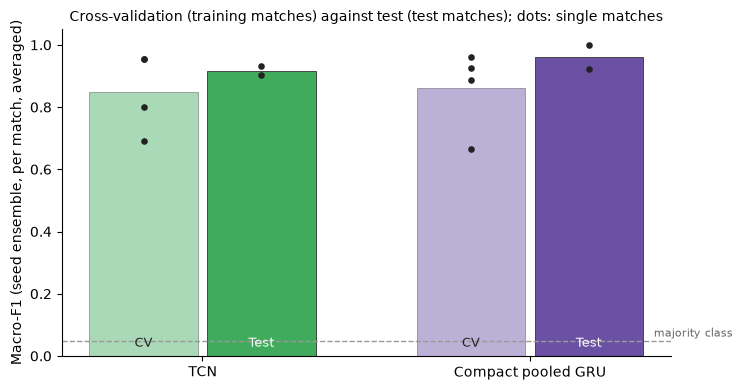

In [7]:
# @title Figure: cross-validation against test, both models
fig, ax = plt.subplots(figsize=(7.5, 4))
width = 0.36
for i, k in enumerate(KINDS):
    for j, (label, values, alpha) in enumerate([("Nested cross-validation", cv[k]["per_match"], 0.45), ("Test", test[k]["per_match"], 1.0)]):
        x = i + (j - 0.5) * width
        ax.bar(x, np.mean(list(values.values())), width * 0.92, color=COLOURS[k], alpha=alpha, edgecolor="#333", linewidth=0.6)
        ax.scatter([x] * len(values), list(values.values()), color="#222", s=14, zorder=3)
        ax.text(x, 0.02, "CV" if j == 0 else "Test", ha="center", va="bottom", fontsize=9, color="white" if j else "#222")
ax.axhline(majority["per_match_mean"], color="#999", linestyle="--", linewidth=1)
ax.text(1.62, majority["per_match_mean"] + 0.015, "majority class", ha="right", fontsize=8, color="#666")
ax.set_xticks(range(len(KINDS)), [MODEL[k] for k in KINDS])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Macro-F1 (seed ensemble, per match, averaged)")
ax.set_title("Cross-validation (training matches) against test (test matches); dots: single matches", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [8]:
# @title Key numbers and checks
say(
    f"**Key numbers:** main test macro-F1 TCN {test['tcn']['mean']:.3f} ± {test['tcn']['sd']:.3f}, GRU {test['gru']['mean']:.3f} ± {test['gru']['sd']:.3f}; "
    f"seed ensemble TCN {test['tcn']['ensemble']['macro_f1']:.3f} (accuracy {test['tcn']['ensemble']['accuracy']:.3f}), "
    f"GRU {test['gru']['ensemble']['macro_f1']:.3f} (accuracy {test['gru']['ensemble']['accuracy']:.3f}); majority class {majority['pooled']['macro_f1']:.3f}. "
    f"Per-match average: TCN cross-validation {cv['tcn']['per_match_mean']:.3f}, test {test['tcn']['per_match_mean']:.3f}; "
    f"GRU cross-validation {cv['gru']['per_match_mean']:.3f}, test {test['gru']['per_match_mean']:.3f}."
)
claims([
    ("on the main test number the two models are within 0.01 of each other", lambda: abs(test["tcn"]["mean"] - test["gru"]["mean"]) < 0.01),
    ("the GRU's seeds vary more on test than the TCN's", lambda: test["gru"]["sd"] > test["tcn"]["sd"]),
    ("the GRU's seed ensemble scores higher on test than the TCN's", lambda: test["gru"]["ensemble"]["macro_f1"] > test["tcn"]["ensemble"]["macro_f1"]),
    ("both models score higher on the test matches than in nested cross-validation, compared per match with the seed ensemble", lambda: all(test[k]["per_match_mean"] > cv[k]["per_match_mean"] for k in KINDS)),
    ("compared this way, the GRU's nested score is slightly above the TCN's, while on the per-seed nested score used for the choice the TCN leads", lambda: 0 < cv["gru"]["per_match_mean"] - cv["tcn"]["per_match_mean"] < 0.02 and cv["tcn"]["nested"] > cv["gru"]["nested"]),
    ("both models score far above the majority-class baseline", lambda: min(test[k]["mean"] for k in KINDS) > majority["pooled"]["macro_f1"] + 0.5),
])

**Key numbers:** main test macro-F1 TCN 0.897 ± 0.009, GRU 0.890 ± 0.030; seed ensemble TCN 0.927 (accuracy 0.933), GRU 0.963 (accuracy 0.956); majority class 0.047. Per-match average: TCN cross-validation 0.850, test 0.917; GRU cross-validation 0.860, test 0.962.

**Checked:** on the main test number the two models are within 0.01 of each other; the GRU's seeds vary more on test than the TCN's; the GRU's seed ensemble scores higher on test than the TCN's; both models score higher on the test matches than in nested cross-validation, compared per match with the seed ensemble; compared this way, the GRU's nested score is slightly above the TCN's, while on the per-seed nested score used for the choice the TCN leads; both models score far above the majority-class baseline.

## 3. Which tactics and matches does each model get right?

Per tactic: precision is how often a prediction of that tactic is right, recall how many of its clips are found, and F1 combines the two. Per match: the macro-F1 and accuracy on each test match alone. Both tables use the seed ensemble, as the app does, so the two models are compared the same way. With only five or six clips in some tactics, one clip moves a tactic's recall by about a fifth.

In [9]:
# @title Table: per tactic, seed ensemble
rows = []
for c in CLASSES:
    t, g = test["tcn"]["ensemble"]["per_class"][c], test["gru"]["ensemble"]["per_class"][c]
    rows.append([c, t["support"], t["precision"], t["recall"], t["f1"], g["precision"], g["recall"], g["f1"]])
show_table("per-tactic", pd.DataFrame(rows, columns=["Tactic", "Test clips", "TCN precision", "TCN recall", "TCN F1", "GRU precision", "GRU recall", "GRU F1"]))

Tactic,Test clips,TCN precision,TCN recall,TCN F1,GRU precision,GRU recall,GRU F1
A_DIRECT,15,0.933,0.933,0.933,0.933,0.933,0.933
B_DIRECT,6,1.000,0.833,0.909,1.000,1.000,1.000
A_SPLIT,6,1.000,1.000,1.000,0.857,1.000,0.923
B_SPLIT,5,0.714,1.000,0.833,1.000,1.000,1.000
RETAKE,13,1.000,0.923,0.960,1.000,0.923,0.960


In [10]:
# @title Table: per test match, seed ensemble
rows = []
for m in TEST_MATCHES:
    keep = matches == m
    rows.append([MATCH_NAMES[m], int(keep.sum()), test["tcn"]["per_match"][m], float((predicted["tcn"][keep] == y[keep]).mean()),
                 test["gru"]["per_match"][m], float((predicted["gru"][keep] == y[keep]).mean()), majority["per_match"][m]])
show_table("per-match", pd.DataFrame(rows, columns=["Match", "Clips", "TCN macro-F1", "TCN accuracy", "GRU macro-F1", "GRU accuracy", "Majority macro-F1"]))

Match,Clips,TCN macro-F1,TCN accuracy,GRU macro-F1,GRU accuracy,Majority macro-F1
NaVi vs Falcons,24,0.931,0.958,1.000,1.000,0.044
Vitality vs Falcons,21,0.902,0.905,0.924,0.905,0.050


In [11]:
# @title Key numbers and checks
f1 = {k: {c: test[k]["ensemble"]["per_class"][c]["f1"] for c in CLASSES} for k in KINDS}
say(
    "**Key numbers:** "
    + "; ".join(f"{MODEL[k]} lowest F1 {min(f1[k], key=f1[k].get)} ({min(f1[k].values()):.3f}), highest {max(f1[k], key=f1[k].get)} ({max(f1[k].values()):.3f})" for k in KINDS)
    + "; per match: " + "; ".join(f"{MATCH_NAMES[m]} TCN {test['tcn']['per_match'][m]:.3f}, GRU {test['gru']['per_match'][m]:.3f}" for m in TEST_MATCHES) + "."
)
recall = {k: {c: test[k]["ensemble"]["per_class"][c]["recall"] for c in CLASSES} for k in KINDS}
claims([
    ("both models find every A_SPLIT and every B_SPLIT clip", lambda: all(recall[k][c] == 1.0 for k in KINDS for c in ("A_SPLIT", "B_SPLIT"))),
    ("both models have the same F1 on A_DIRECT and on RETAKE", lambda: all(abs(f1["tcn"][c] - f1["gru"][c]) < TOLERANCE for c in ("A_DIRECT", "RETAKE"))),
    ("both models score higher on NaVi vs Falcons than on Vitality vs Falcons", lambda: all(test[k]["per_match"]["navi-falcons-mirage-cologne-major"] > test[k]["per_match"]["vitality-falcons-mirage-esl-pro-league-season-24"] for k in KINDS)),
    ("the GRU gets every NaVi vs Falcons clip right", lambda: bool((predicted["gru"][matches == "navi-falcons-mirage-cologne-major"] == y[matches == "navi-falcons-mirage-cologne-major"]).all())),
])

**Key numbers:** TCN lowest F1 B_SPLIT (0.833), highest A_SPLIT (1.000); Compact pooled GRU lowest F1 A_SPLIT (0.923), highest B_DIRECT (1.000); per match: NaVi vs Falcons TCN 0.931, GRU 1.000; Vitality vs Falcons TCN 0.902, GRU 0.924.

**Checked:** both models find every A_SPLIT and every B_SPLIT clip; both models have the same F1 on A_DIRECT and on RETAKE; both models score higher on NaVi vs Falcons than on Vitality vs Falcons; the GRU gets every NaVi vs Falcons clip right.

## 4. Where do they go wrong, and do they agree?

The confusion matrices count the test clips by true tactic (rows) and predicted tactic (columns), for each model's seed ensemble; the diagonal is correct. The agreement table splits the clips by whether the two models give the same answer, and shows how often each is right in each group: this is what the app's second opinion adds. The last table lists every clip that at least one model gets wrong, with the confidence and the "uncertain" flag the app shows.

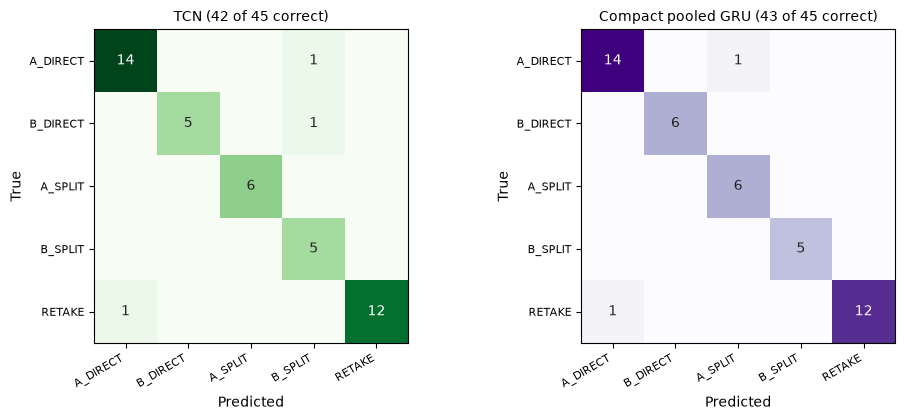

In [12]:
# @title Figure: confusion matrices, seed ensemble (counts)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
short_names = CLASSES
for ax, k in zip(axes, KINDS):
    matrix = np.array(test[k]["ensemble"]["confusion"])
    ax.imshow(matrix, cmap="Greens" if k == "tcn" else "Purples", vmin=0, vmax=matrix.max())
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if matrix[i, j]:
                ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=10, color="white" if matrix[i, j] > matrix.max() / 2 else "#222")
    ax.set_xticks(range(len(CLASSES)), short_names, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(CLASSES)), short_names, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{MODEL[k]} ({int(np.trace(matrix))} of {matrix.sum()} correct)", fontsize=10)
plt.tight_layout()
plt.show()

In [13]:
# @title Table: how often the two models agree
agree = predicted["tcn"] == predicted["gru"]
right = {k: predicted[k] == y for k in KINDS}
rows = [
    ["Same answer", int(agree.sum()), float(right["tcn"][agree].mean()) if agree.any() else float("nan"), float(right["gru"][agree].mean()) if agree.any() else float("nan")],
    ["Different answers", int((~agree).sum()), float(right["tcn"][~agree].mean()) if (~agree).any() else float("nan"), float(right["gru"][~agree].mean()) if (~agree).any() else float("nan")],
]
show_table("agreement", pd.DataFrame(rows, columns=["The two models give", "Clips", "TCN accuracy", "GRU accuracy"]))

The two models give,Clips,TCN accuracy,GRU accuracy
Same answer,43,0.977,0.977
Different answers,2,0.000,0.500


In [14]:
# @title Table: every clip at least one model gets wrong
rows = []
for i, c in enumerate(clips):
    if right["tcn"][i] and right["gru"][i]:
        continue
    a = by_app[c]["predictions"]
    cell = lambda k: f"{a[k]['tactic']} ({a[k]['confidence']:.2f}{', uncertain' if a[k]['uncertain'] else ''})"
    rows.append([short(c), MATCH_NAMES[match_of(c)], CLASSES[y[i]], cell("tcn"), cell("gru")])
errors = pd.DataFrame(rows, columns=["Clip", "Match", "True", "TCN (confidence)", "GRU (confidence)"])
show_table("errors", errors)

Clip,Match,True,TCN (confidence),GRU (confidence)
s022,NaVi vs Falcons,B_DIRECT,B_SPLIT (0.78),B_DIRECT (0.67)
s005,Vitality vs Falcons,RETAKE,"A_DIRECT (0.48, uncertain)",A_DIRECT (0.62)
s016,Vitality vs Falcons,A_DIRECT,"B_SPLIT (0.53, uncertain)","A_SPLIT (0.53, uncertain)"


In [15]:
# @title Key numbers and checks
uncertain = {k: np.array([by_app[c]["predictions"][k]["uncertain"] for c in clips]) for k in KINDS}
say(
    f"**Key numbers:** the models agree on {int(agree.sum())} of {len(clips)} clips; when they agree, both are right on {int((agree & right['tcn']).sum())}; "
    f"when they differ ({int((~agree).sum())} clips), the TCN is right on {int((~agree & right['tcn']).sum())} and the GRU on {int((~agree & right['gru']).sum())}. "
    f"Errors: TCN {int((~right['tcn']).sum())}, GRU {int((~right['gru']).sum())}, both wrong {int((~right['tcn'] & ~right['gru']).sum())}. "
    f"Flagged uncertain by the app: TCN {int(uncertain['tcn'].sum())}, GRU {int(uncertain['gru'].sum())}."
)
claims([
    ("the models give the same answer on all but two clips", lambda: int((~agree).sum()) == 2),
    ("when they agree, they are right on all but one clip", lambda: int((agree & ~right["tcn"]).sum()) == 1),
    ("two clips are wrong for both models", lambda: int((~right["tcn"] & ~right["gru"]).sum()) == 2),
    ("every GRU error is also a TCN error", lambda: bool((~right["tcn"])[~right["gru"]].all())),
    ("the app flags two of the TCN's three errors as uncertain", lambda: int((~right["tcn"]).sum()) == 3 and int((~right["tcn"] & uncertain["tcn"]).sum()) == 2),
])

**Key numbers:** the models agree on 43 of 45 clips; when they agree, both are right on 42; when they differ (2 clips), the TCN is right on 0 and the GRU on 1. Errors: TCN 3, GRU 2, both wrong 2. Flagged uncertain by the app: TCN 4, GRU 2.

**Checked:** the models give the same answer on all but two clips; when they agree, they are right on all but one clip; two clips are wrong for both models; every GRU error is also a TCN error; the app flags two of the TCN's three errors as uncertain.

## 5. How far can this be trusted?

- **The TCN's test set has been looked at before.** The TCN's test results were scored twice during development, before the model comparison finished. Its test score is therefore not fully untouched, even though it did not change the choice of model.
- **The GRU was scored once,** after the TCN had been selected, for this notebook.
- **The test matches share a team with training.** Falcons play in both test matches and in two training matches, so the test is not a test on completely unseen teams.
- **The test set is small:** two matches. One clip changes accuracy by about two points, and some tactics have only five or six clips.
- **The map regions were designed using training labels only.** The regions behind the shared clip features were drawn after looking at training clips and their labels; no test clip shaped them.

The table below sets the scores against the majority-class baseline for scale.

In [16]:
# @title Table: the scores against the majority-class baseline
rows = [[MODEL[k], test[k]["mean"], test[k]["ensemble"]["macro_f1"], test[k]["per_match_mean"]] for k in KINDS]
rows.append([f"Majority class ({majority_class})", majority["pooled"]["macro_f1"], majority["pooled"]["macro_f1"], majority["per_match_mean"]])
show_table("baseline", pd.DataFrame(rows, columns=["Model", "Test macro-F1, pooled (mean over seeds)", "Seed ensemble", "Seed ensemble, per match averaged"]))

Model,"Test macro-F1, pooled (mean over seeds)",Seed ensemble,"Seed ensemble, per match averaged"
TCN,0.897,0.927,0.917
Compact pooled GRU,0.890,0.963,0.962
Majority class (B_DIRECT),0.047,0.047,0.047


In [17]:
# @title Key numbers and checks
teams = lambda m: set(m.split("-mirage")[0].split("-"))
shared = set.intersection(*(teams(m) for m in TEST_MATCHES)) & set.union(*(teams(m) for m in TRAIN_MATCHES))
smallest = min(per_class_n.values())
say(
    f"**Key numbers:** {len(clips)} test clips from {len(TEST_MATCHES)} matches; one clip is {1 / len(clips):.3f} of accuracy; "
    f"smallest tactic {smallest} clips; team in both test matches and in training: {', '.join(sorted(t.title() for t in shared))} "
    f"({sum('falcons' in teams(m) for m in TRAIN_MATCHES)} of {len(TRAIN_MATCHES)} training matches); majority-class macro-F1 {majority['pooled']['macro_f1']:.3f}."
)
claims([
    ("Falcons play in both test matches and in two training matches", lambda: shared == {"falcons"} and sum("falcons" in teams(m) for m in TRAIN_MATCHES) == 2),
    ("the test set has two matches and 45 clips", lambda: len(TEST_MATCHES) == 2 and len(clips) == 45),
    ("one clip changes accuracy by about two points", lambda: 0.015 < 1 / len(clips) < 0.025),
    ("some tactics have only five or six test clips", lambda: smallest in (5, 6)),
    ("both models score far above the majority-class baseline", lambda: min(test[k]["mean"] for k in KINDS) > majority["pooled"]["macro_f1"] + 0.5),
])
say("**From the project's records (not checkable from these files):** the TCN's test results were scored twice during development, before the comparison finished; "
    "the GRU was scored once, after selection; the map regions were drawn using training labels only ([clip data](../docs/clip-data.md#map-regions)).")

**Key numbers:** 45 test clips from 2 matches; one clip is 0.022 of accuracy; smallest tactic 5 clips; team in both test matches and in training: Falcons (2 of 4 training matches); majority-class macro-F1 0.047.

**Checked:** Falcons play in both test matches and in two training matches; the test set has two matches and 45 clips; one clip changes accuracy by about two points; some tactics have only five or six test clips; both models score far above the majority-class baseline.

**From the project's records (not checkable from these files):** the TCN's test results were scored twice during development, before the comparison finished; the GRU was scored once, after selection; the map regions were drawn using training labels only ([clip data](../docs/clip-data.md#map-regions)).

## Appendix A. Files read and how they were made

- **The TCN:** `runs/tactic-tcn-clipdata-final`, made by `train-tactics --clip-data` on the 2026-11-16 export. Its `report.json` holds the test scores per seed and for the seed ensemble; `predictions.csv` holds the seed ensemble's test predictions. Per-seed test predictions were not saved.
- **The GRU:** `runs/tactic-gru-clipdata-final-20261121`, made by `train-gru-final` on the train-only copies ([guide](../docs/gru-predict.md)).
- **The test run:** `runs/tactic-gru-clipdata-test-20261121`, made once by `scripts/final_test_gru.py`. It computes the test clips' features once, exactly as `predict_clips` does (one background per match from that match's clips), checks that `predict_clips(models=("tcn",))` reproduces the TCN's saved test predictions, then runs `predict_clips(models=("gru",))` and each GRU seed on the same features. It trains and tunes nothing.
- **Cross-validation:** the nested runs of the [comparison notebook](tactic-model-comparison.ipynb), `runs/tactic-tcn-clipdata-nested-20261120` and `runs/tactic-clipdata-nested-20261120`, on training matches only.

The notebook reads only these folders; it does not need the clips or the dataset.

```powershell
python scripts/final_test_gru.py --dataset data/processed/datasets/2026-11-16 --output runs/tactic-gru-clipdata-test-<new date>
```

In [18]:
# @title Folders read and environment
import platform

import matplotlib

rows = [[key, path, "found"] for key, path in RUNS.items()]
show_table("folders", pd.DataFrame(rows, columns=["Role", "Folder", "Status"]))
say(f"Test manifest checked by the test run: SHA-256 `{gru_test['test_manifest_sha256'][:16]}…`. "
    f"Notebook kernel: Python {platform.python_version()}; numpy {np.__version__}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}.")

Role,Folder,Status
tcn_final,runs/tactic-tcn-clipdata-final,found
gru_final,runs/tactic-gru-clipdata-final-20261121,found
gru_test,runs/tactic-gru-clipdata-test-20261121,found
tcn_nested,runs/tactic-tcn-clipdata-nested-20261120,found
gru_nested,runs/tactic-clipdata-nested-20261120,found


Test manifest checked by the test run: SHA-256 `c50a94f484430d90…`. Notebook kernel: Python 3.13.15; numpy 2.2.6, pandas 3.0.6, matplotlib 3.11.2.